# Interpretabilidad de las explicaciones según un LLM juez (1,000 correos)

Gráficas a partir de `eval_system/eval_interpretabilidad_juez.jsonl`, generado por
`analysis/eval_interpretabilidad_llm.py`: Claude Haiku 4.5 (temperatura 0) evalúa cada explicación del prototipo en

- `justifica_veredicto`: la explicación respalda la clasificación dada;
- `cita_senales_concretas`: menciona señales específicas del correo, no genéricas;
- `ingenieria_social_identificada`: nombra tácticas de ingeniería social concretas;
- `comprensible_no_tecnico`: 1 (incomprensible) a 5 (muy claro para cualquier usuario).

Las clases corresponden al **label real** del correo (phishing / legítimo), no a la clasificación del prototipo.
Las figuras se guardan en `experiments/analysis/figures/` como PNG a 300 dpi.

## Carga de datos

In [1]:
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEMILLA = 42
COLOR_PHISHING, COLOR_LEGITIMO = "#e74c3c", "#2ecc71"
GRIS = "#4d4d4d"
PALETA = {"Phishing": COLOR_PHISHING, "Legítimo": COLOR_LEGITIMO}
CLASES = ["Phishing", "Legítimo"]
BOOLEANOS = ["justifica_veredicto", "cita_senales_concretas", "ingenieria_social_identificada"]
ETIQUETA = {
    "justifica_veredicto": "Justifica el veredicto",
    "cita_senales_concretas": "Cita señales concretas",
    "ingenieria_social_identificada": "Identifica ingeniería social",
}

# Estilo académico: fuente de 11 pt, sin rejilla ni bordes superiores/derechos
mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "font.family": "sans-serif",
})

# Carpeta experiments/ (funciona desde experiments/analysis/, experiments/ o la raíz del repo)
BASE = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / "experiments"] if (p / "eval_system").exists())
RUTA_JUEZ = BASE / "eval_system" / "eval_interpretabilidad_juez.jsonl"
FIG_DIR = BASE / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    # Guarda la figura como PNG a 300 dpi
    fig.savefig(FIG_DIR / f"{nombre}.png")
    print("Guardada:", (FIG_DIR / f"{nombre}.png").relative_to(BASE.parent).as_posix())


with open(RUTA_JUEZ, encoding="utf-8") as f:
    df = pd.DataFrame([json.loads(linea) for linea in f if linea.strip()])

# Se excluyen los registros en los que el juez no devolvió un JSON válido
n_total = len(df)
if "juez_error" in df.columns:
    df = df[df["juez_error"].isna()].copy()
df["clase"] = df["label_real"].map({1: "Phishing", 0: "Legítimo"})
df["comprensible_no_tecnico"] = df["comprensible_no_tecnico"].astype(int)
df[BOOLEANOS] = df[BOOLEANOS].astype(bool)
ph, lg = df[df["clase"] == "Phishing"], df[df["clase"] == "Legítimo"]

print(f"Registros: {n_total} | evaluados por el juez: {len(df)} | con juez_error: {n_total - len(df)}")
print(f"Phishing (label real): {len(ph)} | Legítimo (label real): {len(lg)}")

Registros: 1000 | evaluados por el juez: 1000 | con juez_error: 0
Phishing (label real): 500 | Legítimo (label real): 500


## 1. Distribución de `comprensible_no_tecnico` por clase

Guardada: experiments/analysis/figures/fig1_distribucion_comprensible_por_clase.png


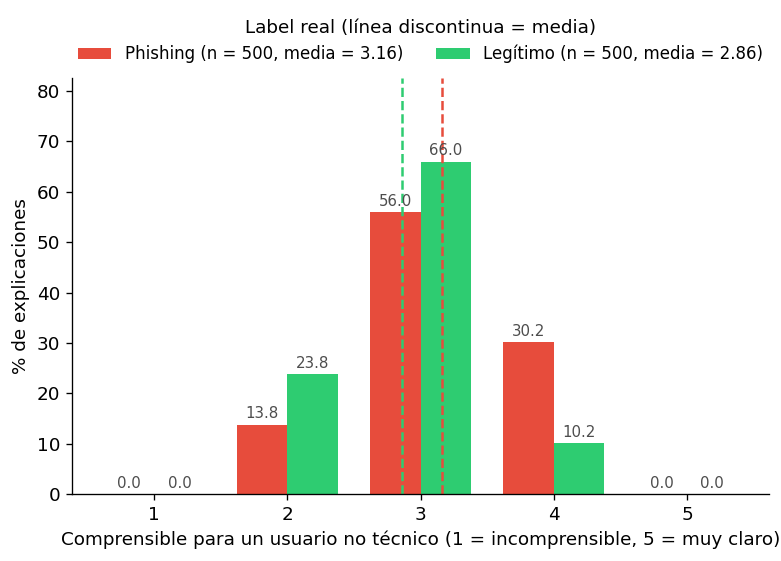

,Phishing,Legítimo
puntaje,,
1,0.0,0.0
2,13.8,23.8
3,56.0,66.0
4,30.2,10.2
5,0.0,0.0


In [2]:
# % de explicaciones en cada puntaje (1-5) por clase; la línea discontinua marca la media de cada clase
puntajes = np.arange(1, 6)
dist = pd.DataFrame({c: d["comprensible_no_tecnico"].value_counts(normalize=True).reindex(puntajes, fill_value=0) * 100
                     for c, d in [("Phishing", ph), ("Legítimo", lg)]})

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ancho = 0.38
for i, clase in enumerate(CLASES):
    media = df.loc[df["clase"] == clase, "comprensible_no_tecnico"].mean()
    barras = ax.bar(puntajes + (i - 0.5) * ancho, dist[clase], ancho, color=PALETA[clase],
                    label=f"{clase} (n = {(df['clase'] == clase).sum()}, media = {media:.2f})")
    ax.bar_label(barras, fmt="%.1f", padding=2, fontsize=9, color=GRIS)
    ax.axvline(media, color=PALETA[clase], linestyle="--", linewidth=1.5)
ax.set_xticks(puntajes)
ax.set_xlabel("Comprensible para un usuario no técnico (1 = incomprensible, 5 = muy claro)")
ax.set_ylabel("% de explicaciones")
ax.set_ylim(0, dist.to_numpy().max() * 1.25)
ax.legend(frameon=False, title="Label real (línea discontinua = media)", loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
guardar(fig, "fig1_distribucion_comprensible_por_clase")
plt.show()
display(dist.round(1).rename_axis("puntaje"))

## 2. Porcentaje de campos booleanos por clase

Guardada: experiments/analysis/figures/fig2_booleanos_por_clase.png


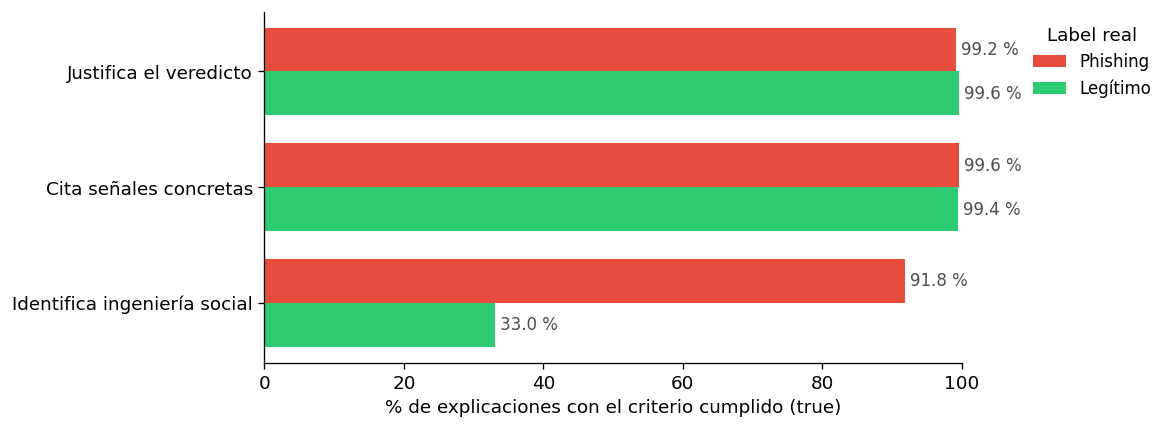

clase,Phishing,Legítimo
justifica_veredicto,99.2,99.6
cita_senales_concretas,99.6,99.4
ingenieria_social_identificada,91.8,33.0


In [3]:
# % de explicaciones con cada criterio en true, phishing y legítimo lado a lado
pct_bool = df.groupby("clase")[BOOLEANOS].mean().T.mul(100)[CLASES]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(BOOLEANOS))
alto = 0.38
for i, clase in enumerate(CLASES):
    barras = ax.barh(y + (i - 0.5) * alto, pct_bool[clase], alto, color=PALETA[clase], label=clase)
    ax.bar_label(barras, fmt="%.1f %%", padding=3, fontsize=10, color=GRIS)
ax.set_yticks(y)
ax.set_yticklabels([ETIQUETA[b] for b in BOOLEANOS])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% de explicaciones con el criterio cumplido (true)")
ax.legend(frameon=False, title="Label real", loc="upper left", bbox_to_anchor=(1.08, 1.0))
guardar(fig, "fig2_booleanos_por_clase")
plt.show()
display(pct_bool.round(1))

## 3. Heatmap de combinaciones booleanas

Guardada: experiments/analysis/figures/fig3_heatmap_combinaciones_booleanas.png


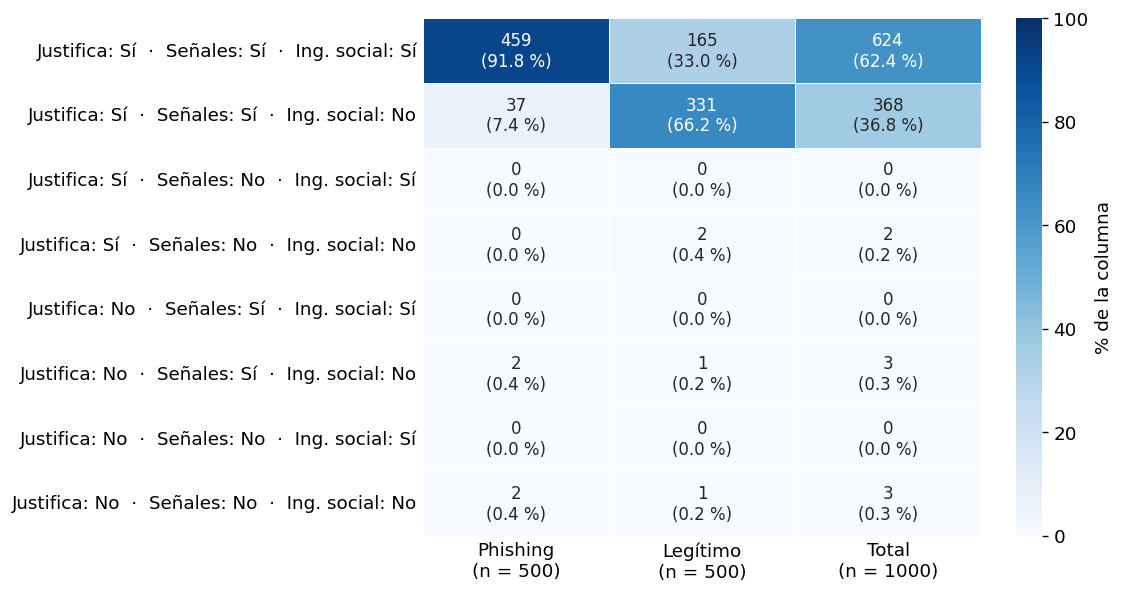

In [4]:
# Frecuencia de las 8 combinaciones posibles de los 3 booleanos, por clase y en total
combinaciones = pd.MultiIndex.from_product([[True, False]] * 3, names=BOOLEANOS)
conteo = (df.groupby(BOOLEANOS + ["clase"]).size().unstack("clase", fill_value=0)
          .reindex(combinaciones, fill_value=0).reindex(columns=CLASES, fill_value=0))
conteo["Total"] = conteo.sum(axis=1)
porcentaje = conteo / conteo.sum(axis=0) * 100

si_no = lambda v: "Sí" if v else "No"
filas = [f"Justifica: {si_no(j)}  ·  Señales: {si_no(c)}  ·  Ing. social: {si_no(s)}" for j, c, s in conteo.index]
anotaciones = np.array([[f"{conteo.iat[i, k]}\n({porcentaje.iat[i, k]:.1f} %)" for k in range(conteo.shape[1])]
                        for i in range(conteo.shape[0])])

fig, ax = plt.subplots(figsize=(7.5, 5.6))
sns.heatmap(porcentaje, annot=anotaciones, fmt="", cmap="Blues", vmin=0, vmax=100, linewidths=0.6, linecolor="white",
            cbar_kws={"label": "% de la columna"}, annot_kws={"fontsize": 10}, ax=ax)
ax.set_yticklabels(filas, rotation=0)
ax.set_xticklabels([f"{c}\n(n = {conteo[c].sum()})" for c in conteo.columns], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(length=0)
guardar(fig, "fig3_heatmap_combinaciones_booleanas")
plt.show()

## 4. Puntaje de riesgo frente a `comprensible_no_tecnico`

Guardada: experiments/analysis/figures/fig4_scatter_riesgo_vs_comprensible.png


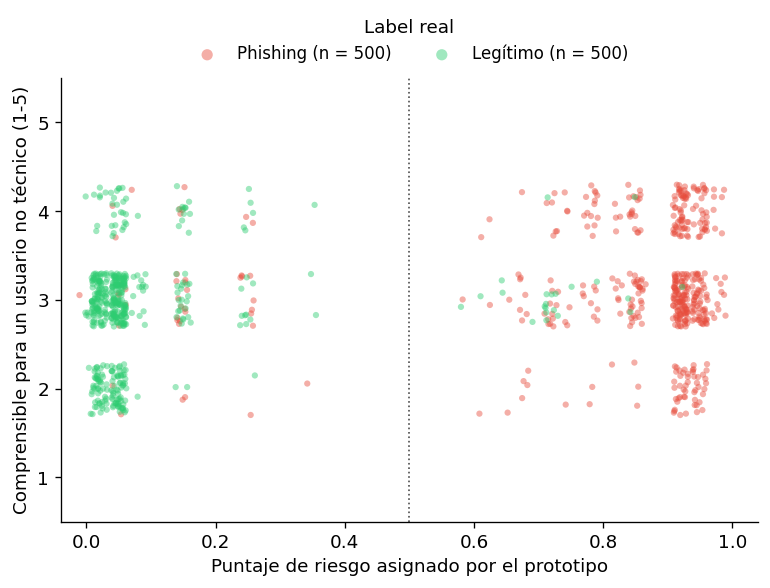

Correlación de Spearman entre puntaje_riesgo y comprensible_no_tecnico: 0.252


In [5]:
# El puntaje del juez es entero, así que se añade jitter (sobre todo vertical) para separar puntos superpuestos
rng = np.random.default_rng(SEMILLA)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for clase in CLASES:
    sub = df[df["clase"] == clase]
    ax.scatter(sub["puntaje_riesgo"] + rng.uniform(-0.012, 0.012, len(sub)),
               sub["comprensible_no_tecnico"] + rng.uniform(-0.3, 0.3, len(sub)),
               s=14, alpha=0.45, color=PALETA[clase], edgecolors="none", label=f"{clase} (n = {len(sub)})")
ax.axvline(0.5, color=GRIS, linestyle=":", linewidth=1)
ax.set_yticks(puntajes)
ax.set_ylim(0.5, 5.5)
ax.set_xlim(-0.04, 1.04)
ax.set_xlabel("Puntaje de riesgo asignado por el prototipo")
ax.set_ylabel("Comprensible para un usuario no técnico (1-5)")
ax.legend(frameon=False, title="Label real", loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, markerscale=1.8)
guardar(fig, "fig4_scatter_riesgo_vs_comprensible")
plt.show()

rho = df[["puntaje_riesgo", "comprensible_no_tecnico"]].corr(method="spearman").iat[0, 1]
print(f"Correlación de Spearman entre puntaje_riesgo y comprensible_no_tecnico: {rho:.3f}")

## 5. Tabla resumen

,Phishing,Legítimo,Global
n,500,500,1000
Comprensible (media ± DE),3.16 ± 0.64,2.86 ± 0.57,3.01 ± 0.62
Justifica el veredicto (% true),99.2 %,99.6 %,99.4 %
Cita señales concretas (% true),99.6 %,99.4 %,99.5 %
Identifica ingeniería social (% true),91.8 %,33.0 %,62.4 %


Guardada: experiments/analysis/figures/fig5_tabla_resumen.png


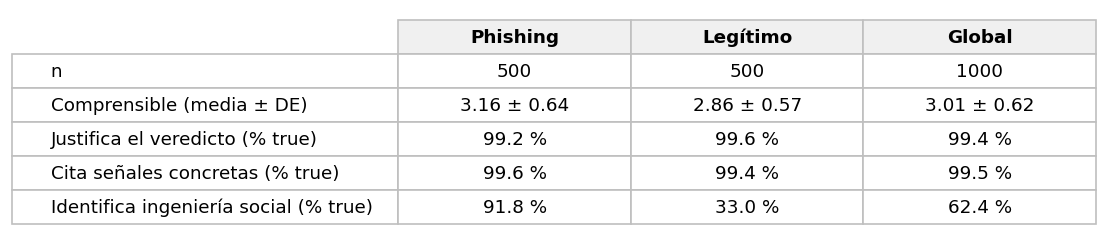

In [6]:
# Media ± desviación estándar de comprensible_no_tecnico y % true de cada booleano, por clase
def resumen_clase(d):
    fila = {"n": f"{len(d)}",
            "Comprensible (media ± DE)": f"{d['comprensible_no_tecnico'].mean():.2f} ± {d['comprensible_no_tecnico'].std():.2f}"}
    fila.update({f"{ETIQUETA[b]} (% true)": f"{100 * d[b].mean():.1f} %" for b in BOOLEANOS})
    return fila

tabla = pd.DataFrame({"Phishing": resumen_clase(ph), "Legítimo": resumen_clase(lg), "Global": resumen_clase(df)})
display(tabla)

fig, ax = plt.subplots(figsize=(7.5, 2.4))
ax.axis("off")
t = ax.table(cellText=tabla.values, rowLabels=tabla.index, colLabels=tabla.columns, cellLoc="center", loc="center")
t.auto_set_font_size(False)
t.set_fontsize(11)
t.scale(1, 1.7)
for (fila, col), celda in t.get_celld().items():
    celda.set_edgecolor("#bfbfbf")
    if fila == 0:
        celda.set_text_props(weight="bold")
        celda.set_facecolor("#f0f0f0")
guardar(fig, "fig5_tabla_resumen")
plt.show()

## Métricas clave para la tesis

In [7]:
# Formato copiable: phishing / legítimo según el label real
par = lambda f: f"{f(ph):.1f} % / {f(lg):.1f} %"
print(f"Explicaciones evaluadas: {len(df)} (phishing = {len(ph)}, legítimo = {len(lg)})")
print(f"% con comprensible_no_tecnico >= 4 (phishing / legítimo): {par(lambda d: 100 * (d['comprensible_no_tecnico'] >= 4).mean())}")
print(f"% justifica_veredicto true (phishing / legítimo): {par(lambda d: 100 * d['justifica_veredicto'].mean())}")
print(f"% ingenieria_social_identificada true (phishing / legítimo): {par(lambda d: 100 * d['ingenieria_social_identificada'].mean())}")
print(f"Media de comprensible_no_tecnico global: {df['comprensible_no_tecnico'].mean():.2f} "
      f"(DE = {df['comprensible_no_tecnico'].std():.2f}; phishing = {ph['comprensible_no_tecnico'].mean():.2f}, "
      f"legítimo = {lg['comprensible_no_tecnico'].mean():.2f})")

Explicaciones evaluadas: 1000 (phishing = 500, legítimo = 500)
% con comprensible_no_tecnico >= 4 (phishing / legítimo): 30.2 % / 10.2 %
% justifica_veredicto true (phishing / legítimo): 99.2 % / 99.6 %
% ingenieria_social_identificada true (phishing / legítimo): 91.8 % / 33.0 %
Media de comprensible_no_tecnico global: 3.01 (DE = 0.62; phishing = 3.16, legítimo = 2.86)
